# AllBirds Beacon

In [3]:
import os
if not os.path.exists('catalog.json'):
    try:
        from google.colab import files
        uploaded = files.upload()
    except ImportError:
        print('place the json files in the cwd.')

In [4]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr, pearsonr

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
np.random.seed(42)

In [6]:
def load_json(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def load_table(stem):
    """Prefer parquet; fall back to jsonl lines."""
    pq, jl = Path(f'{stem}.parquet'), Path(f'{stem}.jsonl')
    if pq.exists():
        return pd.read_parquet(pq)
    if jl.exists():
        return pd.read_json(jl, lines=True)
    raise FileNotFoundError(f'Need {pq.name} or {jl.name} in cwd')

catalog = pd.DataFrame(load_json('catalog.json'))
metrics = load_table('daily_metrics')
truth   = load_table('ground_truth')

metrics['date'] = pd.to_datetime(metrics['date'])
truth['date']   = pd.to_datetime(truth['date'])

# Merge truth columns that are not already on metrics (avoid sales/stock_* collision)
truth_cols = ['date', 'sku_id', 'journey_demand', 'purchase_attempts',
              'lost_units', 'strong_oos_intents', 'availability']
df = metrics.merge(truth[truth_cols], on=['date', 'sku_id'], how='left')

print(f'catalog: {catalog.shape}')
print(f'metrics: {metrics.shape}')
print(f'truth:   {truth.shape}')
print(f'merged:  {df.shape}')
df.head()

catalog: (9300, 9)
metrics: (65100, 17)
truth:   (65100, 16)
merged:  (65100, 22)


,date,sku_id,variant_id,product_id,product_name,colour,size,subcategory,stock_start,stock_end,...,add_to_cart,add_to_wishlist,add_back_in_stock_alert,add_price_drop_alert,price,journey_demand,purchase_attempts,lost_units,strong_oos_intents,availability
0,2026-09-22,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole,Men's Wool Runner - Natural Black (Black Sole),Mens Wool Runners Natural Black,UK 7,running,233,233,...,0,0,0,0,110,0,0,0,0,1
1,2026-09-22,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole,Men's Wool Runner - Natural Black (Black Sole),Mens Wool Runners Natural Black,UK 8,running,330,330,...,0,0,0,0,110,0,0,0,0,1
2,2026-09-22,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole,Men's Wool Runner - Natural Black (Black Sole),Mens Wool Runners Natural Black,UK 12,running,54,54,...,0,0,0,0,110,0,0,0,0,1
3,2026-09-22,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole,Men's Wool Runner - Natural Black (Black Sole),Mens Wool Runners Natural Black,UK 13,running,164,164,...,0,0,0,0,110,0,0,0,0,1
4,2026-09-22,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole__...,P_men_s_wool_runner_natural_black_black_sole,Men's Wool Runner - Natural Black (Black Sole),Mens Wool Runners Natural Black,UK 9,running,0,0,...,0,0,0,0,110,0,0,0,0,0


In [7]:
assert df['journey_demand'].notna().all(), 'Missing ground truth rows'
assert (df['sales'] >= 0).all()
assert (df['stock_start'] >= 0).all()

print('Date range:', df['date'].min().date(), '→', df['date'].max().date())
print('Unique SKUs:', df['sku_id'].nunique())
print('Unique products:', df['product_id'].nunique())
print('Subcategories:', df['subcategory'].unique().tolist())
print('Days per SKU (mean):', df.groupby('sku_id').size().mean().round(1))


Date range: 2026-09-22 → 2026-09-28
Unique SKUs: 9300
Unique products: 817
Subcategories: ['running', 'accessories', 'shoes', 'socks', 'apparel', 'slip_on', 'sandals']
Days per SKU (mean): 7.0


## Analysis



In [9]:
sku_stats = df.groupby(
    ['sku_id','product_id','product_name','colour','size','subcategory']
).agg(
    days_observed=('date','count'),
    total_journey_demand=('journey_demand','sum'),
    total_sales=('sales','sum'),
    total_lost_units=('lost_units','sum'),
    mean_stock=('stock_start','mean'),
    zero_stock_days=('stock_start', lambda x: (x == 0).sum()),
    mean_availability=('availability','mean'),
    total_page_views=('page_views','sum'),
    total_wishlist=('add_to_wishlist','sum'),
    total_bistock=('add_back_in_stock_alert','sum'),
    total_pricedrop=('add_price_drop_alert','sum'),
    total_cart=('add_to_cart','sum'),
).reset_index()

sku_stats['stockout_rate'] = sku_stats['zero_stock_days'] / sku_stats['days_observed']
sku_stats['lost_units_pct'] = (sku_stats['total_lost_units']
                               / sku_stats['total_journey_demand'].clip(lower=1e-6))

sku_stats.sort_values('total_journey_demand', ascending=False).head(10)


,sku_id,product_id,product_name,colour,size,subcategory,days_observed,total_journey_demand,total_sales,total_lost_units,mean_stock,zero_stock_days,mean_availability,total_page_views,total_wishlist,total_bistock,total_pricedrop,total_cart,stockout_rate,lost_units_pct
1484,P_men_s_runner_chelsea_protect_natural_black_n...,P_men_s_runner_chelsea_protect_natural_black_n...,Men's Runner Chelsea Protect - Natural Black (...,Mens Runner Chelsea Protect,UK 8,running,7,15,15,0,107.428571,0,1.0,74,10,0,5,13,0.0,0.000000
2656,P_men_s_tree_runner_go_deep_navy_blizzard_sole...,P_men_s_tree_runner_go_deep_navy_blizzard_sole,Men's Tree Runner Go - Deep Navy (Blizzard Sole),Mens Tree Runner Go Deep Navy,UK 12,running,7,10,0,0,0.000000,7,0.0,5,4,1,1,2,1.0,0.000000
6534,P_women_s_tree_breezer_warm_camel_dark_anthrac...,P_women_s_tree_breezer_warm_camel_dark_anthrac...,Women's Tree Breezer - Warm Camel (Dark Anthra...,Womens Tree Breezer Warm Camel Dark,UK 7.5,shoes,7,7,0,3,0.000000,7,0.0,8,1,1,1,1,1.0,0.428571
850,P_men_s_cruiser_mid_explore_hazy_burgundy_rust...,P_men_s_cruiser_mid_explore_hazy_burgundy_rust...,Men's Cruiser Mid Explore - Hazy Burgundy (Rus...,Mens Cruiser Mid Explore Hazy Burgundy,UK 13,slip_on,7,7,0,4,0.000000,7,0.0,3,0,1,1,3,1.0,0.571429
9208,P_women_s_wool_runner_up_mizzle_stony_cream_na...,P_women_s_wool_runner_up_mizzle_stony_cream_na...,Women's Wool Runner-up Mizzle - Stony Cream (N...,Womens Wool Runner Up Mizzles Stony Cream,UK 5,running,7,7,0,1,0.000000,7,0.0,4,3,1,0,1,1.0,0.142857
693,P_men_s_courier_natural_black_natural_white_so...,P_men_s_courier_natural_black_natural_white_sole,Men's Courier - Natural Black (Natural White S...,Mens Couriers Natural Black White,UK 10,shoes,7,7,0,3,0.000000,7,0.0,4,1,0,0,3,1.0,0.428571
4705,P_women_s_canvas_cruiser_slip_on_auburn_warm_w...,P_women_s_canvas_cruiser_slip_on_auburn_warm_w...,Women's Canvas Cruiser Slip On - Auburn (Warm ...,Canvas Auburn,UK 2.5,slip_on,7,7,0,1,0.000000,7,0.0,8,1,0,0,0,1.0,0.142857
8904,P_women_s_wool_runner_nz_medium_grey_blizzard_...,P_women_s_wool_runner_nz_medium_grey_blizzard_...,Women's Wool Runner NZ - Medium Grey (Blizzard...,Womens Wool Runner Nz Medium Grey,UK 2.5,running,7,6,6,0,132.142857,0,1.0,19,5,0,3,4,0.0,0.000000
3080,P_men_s_tree_skipper_jet_black_white_sole__men...,P_men_s_tree_skipper_jet_black_white_sole,Men's Tree Skipper - Jet Black (White Sole),Mens Tree Skippers Jet Black,UK 9,shoes,7,6,0,3,0.000000,7,0.0,6,1,1,0,1,1.0,0.500000
3343,P_men_s_varsity_terralux_toasted_coconut_toast...,P_men_s_varsity_terralux_toasted_coconut_toast...,Men's Varsity Terralux™ - Toasted Coconut (Toa...,Mens Varsity Terralux Toasted Coconut,UK 13,shoes,7,6,0,1,0.000000,7,0.0,5,1,0,1,1,1.0,0.166667


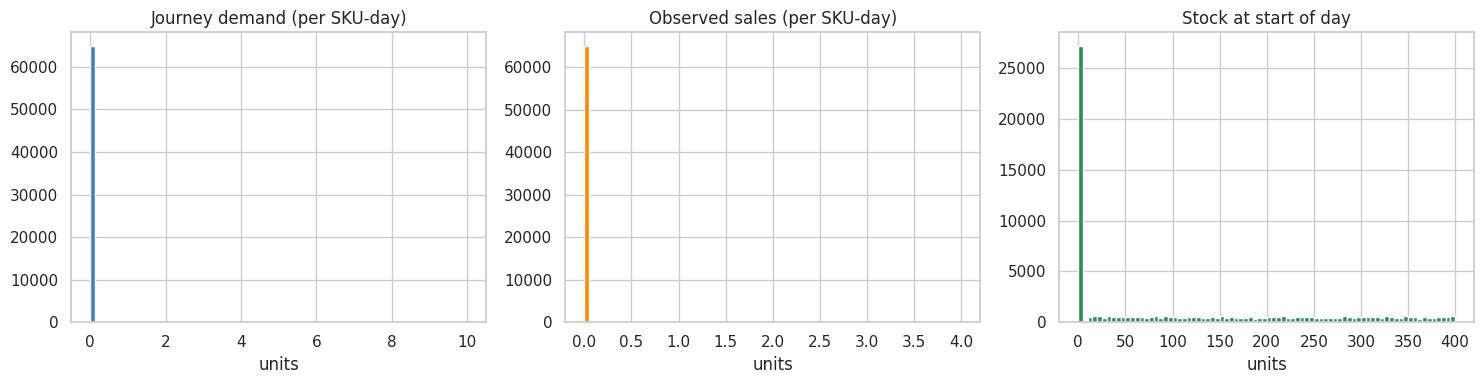

Journey demand — mean, median, p95, max: 0.01 0.0 0.0 10


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df['journey_demand'], bins=80, color='steelblue')
axes[0].set_title('Journey demand (per SKU-day)')
axes[0].set_xlabel('units')
axes[1].hist(df['sales'], bins=80, color='darkorange')
axes[1].set_title('Observed sales (per SKU-day)')
axes[1].set_xlabel('units')
axes[2].hist(df['stock_start'], bins=80, color='seagreen')
axes[2].set_title('Stock at start of day')
axes[2].set_xlabel('units')
plt.tight_layout(); plt.show()

print('Journey demand — mean, median, p95, max:',
      df['journey_demand'].mean().round(2),
      df['journey_demand'].median(),
      df['journey_demand'].quantile(0.95).round(2),
      df['journey_demand'].max())


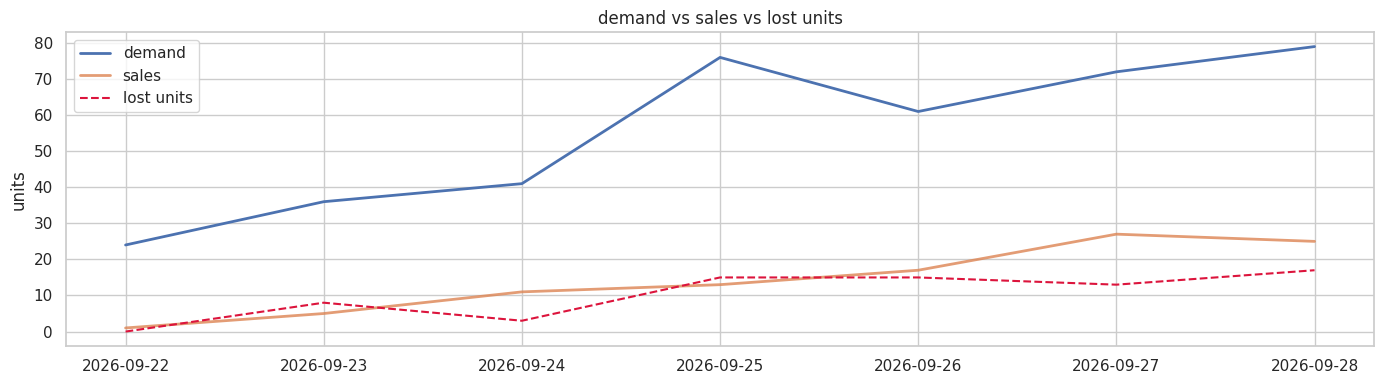

In [16]:
daily = df.groupby('date').agg(
    demand=('journey_demand','sum'),
    sales=('sales','sum'),
    lost=('lost_units','sum'),
    pv=('page_views','sum'),
    wishlist=('add_to_wishlist','sum'),
    bistock=('add_back_in_stock_alert','sum'),
).reset_index()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily['date'], daily['demand'], label='demand', lw=2)
ax.plot(daily['date'], daily['sales'], label='sales', lw=2, alpha=0.8)
ax.plot(daily['date'], daily['lost'], label='lost units', lw=1.5,
        linestyle='--', color='crimson')
ax.set_title('demand vs sales vs lost units')
ax.set_ylabel('units')
ax.legend()
plt.tight_layout(); plt.show()


## 3. Motivation for the problem

This section quantifies the magnitude of the problem.

In [19]:
total_demand = df['journey_demand'].sum()
total_sales  = df['sales'].sum()
total_lost   = df['lost_units'].sum()
oos_days     = (df['stock_start'] == 0).sum()
low_stock    = (df['stock_start'] < df['journey_demand']).sum()

print(f'Total demand:  {total_demand:>10,.0f} units')
print(f'Total observed sales:  {total_sales:>10,.0f} units')
print(f'Total lost units:      {total_lost:>10,.0f} ({total_lost/total_demand*100:.1f}%)')
print(f'SKU-days with zero stock:  {oos_days:,} ({oos_days/len(df)*100:.1f}%)')
print(f'SKU-days stock < demand:   {low_stock:,} ({low_stock/len(df)*100:.1f}%)')


Total demand:         389 units
Total observed sales:          99 units
Total lost units:              71 (18.3%)
SKU-days with zero stock:  27,139 (41.7%)
SKU-days stock < demand:   155 (0.2%)


## 4. Intent-Signal information content

In [22]:
signals = ['page_views','add_to_cart','add_to_wishlist',
           'add_back_in_stock_alert','add_price_drop_alert','sales']

rows = []
for s in signals:
    r_p, _ = pearsonr(df[s], df['journey_demand'])
    r_s, _ = spearmanr(df[s], df['journey_demand'])
    rows.append({'signal': s, 'pearson': round(r_p,3), 'spearman': round(r_s,3)})
sig_corr = pd.DataFrame(rows).sort_values('spearman', ascending=False)
sig_corr


,signal,pearson,spearman
0,page_views,0.557,0.668
5,sales,0.400,0.575
3,add_back_in_stock_alert,0.519,0.478
1,add_to_cart,0.446,0.352
2,add_to_wishlist,0.394,0.330
4,add_price_drop_alert,0.315,0.204


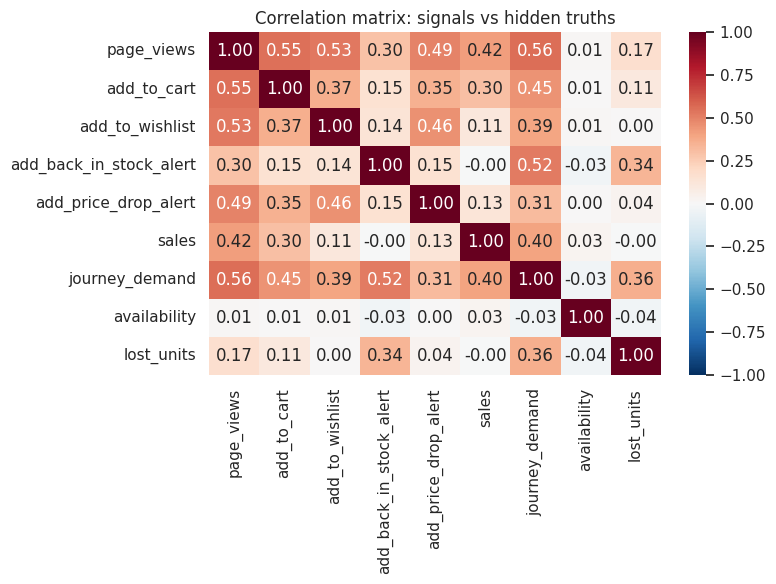

In [23]:
corr_cols = signals + ['journey_demand','availability','lost_units']
plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlation matrix: signals vs hidden truths')
plt.tight_layout(); plt.show()


## 5. Product Archetypes for Merchant Investigation

Section 11 evaluated demand estimates. This section answers a different question:
**which products require which merchant actions?**

| Set | Definition | Merchant action |
|---|---|---|
| **A — Availability Risk** | Currently unavailable AND rising external interest | Expedite restock; trigger back-in-stock notifications |
| **B — Discovery Opportunity** | High intent that catalog attributes don't adequately serve | Expand attribute coverage; targeted collection |
| **C — Needs Investigation** | High public popularity signal but unreliable commercial data | Manual review of inventory integration, content quality |

### Proxy substitutions (declared)

The synthetic dataset contains no external search logs and no public review sites.
Two substitutions are used and are declared explicitly:

- **External search interest** → proxied by the **page-view trend** (last 14 days vs prior 14 days).
- **Public reviews / social proof** → proxied by **wishlist adds, back-in-stock requests, price-drop requests**.

All three product sets are defined **only over observable data** — `ground_truth` is not used to compute membership. Ground truth is used afterwards only for sanity-checking aggregates.

In [25]:
df = df.sort_values(['product_id', 'date']).reset_index(drop=True)

max_date     = df['date'].max()
recent_start = max_date - pd.Timedelta(days=13)
prior_end    = recent_start - pd.Timedelta(days=1)
prior_start  = prior_end - pd.Timedelta(days=13)

def _window_agg(g, s, e):
    w = g[(g['date'] >= s) & (g['date'] <= e)]
    return pd.Series({
        'pv':       w['page_views'].sum(),
        'wl':       w['add_to_wishlist'].sum(),
        'ca':       w['add_to_cart'].sum(),
        'bi':       w['add_back_in_stock_alert'].sum(),
        'pdalert':  w['add_price_drop_alert'].sum(),
        'sales':    w['sales'].sum(),
        'demand':   w['journey_demand'].sum(),
        'lost':     w['lost_units'].sum(),
        'stockout': (w['stock_start'] == 0).mean(),
        'avail':    w['availability'].mean(),
    })

recent = df.groupby('product_id').apply(
    lambda g: _window_agg(g, recent_start, max_date)
).add_prefix('r_')
prior  = df.groupby('product_id').apply(
    lambda g: _window_agg(g, prior_start, prior_end)
).add_prefix('p_')

base = (df.groupby('product_id')
          .agg(product_name=('product_name','first'),
               subcategory=('subcategory','first'),
               n_skus=('sku_id','nunique'),
               n_colours=('colour','nunique'))
          .reset_index())

cat_avail = (catalog.groupby('product_id')['available_in_scrape']
                    .mean().rename('catalog_avail_ratio'))
base = base.merge(cat_avail, on='product_id', how='left')
base['catalog_size_gap'] = 1 - base['catalog_avail_ratio'].fillna(0)

prod = (base.merge(recent, left_on='product_id', right_index=True)
            .merge(prior,  left_on='product_id', right_index=True))

prod['pv_trend']        = ((prod['r_pv'] - prod['p_pv'])
                           / prod['p_pv'].clip(lower=1))
prod['intent_recent']   = prod['r_wl'] + prod['r_ca'] + prod['r_pdalert']
prod['intent_prior']    = prod['p_wl'] + prod['p_ca'] + prod['p_pdalert']
prod['intent_trend']    = ((prod['intent_recent'] - prod['intent_prior'])
                           / prod['intent_prior'].clip(lower=1))
prod['intent_to_sales'] = prod['intent_recent'] / prod['r_sales'].clip(lower=1)
prod['wl_per_view']     = prod['r_wl'] / prod['r_pv'].clip(lower=1)
prod['cart_per_view']   = prod['r_ca'] / prod['r_pv'].clip(lower=1)
prod['bistock_density'] = prod['r_bi'] / prod['r_demand'].clip(lower=1)

print(f'Products:      {len(prod)}')
print(f'Recent window: {recent_start.date()} → {max_date.date()}')
print(f'Prior window:  {prior_start.date()} → {prior_end.date()}')
prod[['product_name','r_pv','pv_trend','r_stockout',
      'catalog_size_gap','r_wl','r_sales']].head(8).round(3)


Products:      817
Recent window: 2026-09-15 → 2026-09-28
Prior window:  2026-09-01 → 2026-09-14


,product_name,r_pv,pv_trend,r_stockout,catalog_size_gap,r_wl,r_sales
0,54,0.0,0.0,0.143,0.143,0.0,0.0
1,Allbirds Laces - Blizzard - Flat,0.0,0.0,0.000,0.000,0.0,0.0
2,Allbirds Laces - Blizzard - Round,0.0,0.0,0.000,0.000,0.0,0.0
3,Allbirds Laces - Dark Navy - Flat,0.0,0.0,0.000,0.000,0.0,0.0
4,Allbirds Laces - Dark Navy - Round,0.0,0.0,0.000,0.000,0.0,0.0
5,Allbirds Laces - Natural Grey Heather - Flat,0.0,0.0,0.000,0.000,0.0,0.0
6,Allbirds Laces - Natural Grey Heather - Round,0.0,0.0,0.000,0.000,0.0,0.0
7,Allbirds Laces - True Black - Flat,0.0,0.0,0.000,0.000,0.0,0.0


In [26]:
# Product A — Availability Risk ----
STOCKOUT_THRESHOLD = 0.50
TREND_THRESHOLD    = 0.10

mask_a = ((prod['r_stockout'] >= STOCKOUT_THRESHOLD)
          & (prod['pv_trend'] >= TREND_THRESHOLD))

prod['A_availability_risk'] = mask_a
prod['A_score'] = (np.log1p(prod['r_lost'].clip(lower=0))
                   * prod['r_stockout']
                   * (1 + prod['pv_trend'].clip(lower=0)))

product_a = (prod[mask_a]
             .sort_values('A_score', ascending=False)
             .reset_index(drop=True))

print(f'Product A — Availability Risk:  {len(product_a)} items')
cols_a = ['product_name','subcategory','r_stockout','pv_trend',
          'r_lost','catalog_size_gap','r_bi','A_score']
product_a[cols_a].head(15).round(3)

Product A — Availability Risk:  133 items


,product_name,subcategory,r_stockout,pv_trend,r_lost,catalog_size_gap,r_bi,A_score
0,Men's Canvas Piper - Natural Black (Blizzard),shoes,1.000,11.0,3.0,1.000,2.0,16.636
1,Men's Cruiser Slip On - Deep Navy (Natural Whi...,slip_on,1.000,7.0,3.0,1.000,2.0,11.090
2,Men's Cruiser Tweed - Dark Grey (Stormy Grey S...,slip_on,1.000,6.0,3.0,1.000,2.0,9.704
3,Men's Courier - Natural Black (Natural White S...,shoes,1.000,6.0,3.0,1.000,0.0,9.704
4,Men's Tree Skipper - Jet Black (White Sole),shoes,1.000,6.0,3.0,1.000,1.0,9.704
5,Men's Tree Runner Go - Deep Navy (Blizzard Sole),running,1.000,12.0,1.0,1.000,3.0,9.011
6,Women's Tree Breezer - Warm Camel (Dark Anthra...,shoes,0.714,8.0,3.0,0.714,1.0,8.912
7,Men's Canvas Cruiser Slip On - Anthracite (Nat...,slip_on,1.000,5.0,2.0,1.000,0.0,6.592
8,Women's Tree Runner - Hazy Indigo (Blizzard Sole),running,1.000,5.0,2.0,1.000,1.0,6.592
9,Women's Canvas Cruiser Slip On - Auburn (Warm ...,slip_on,1.000,8.0,1.0,1.000,0.0,6.238


In [27]:
# Product B — Discovery Opportunity ----
high_intent = prod['r_pv'] > prod['r_pv'].quantile(0.75)
poor_fit    = ((prod['catalog_size_gap'] > 0.30)
               | (prod['cart_per_view'] < prod['cart_per_view'].median() * 0.5))

mask_b = high_intent & poor_fit

prod['B_discovery_opportunity'] = mask_b
prod['B_score'] = (np.log1p(prod['r_pv'])
                   * (1 + prod['catalog_size_gap'].clip(lower=0))
                   * (1 + prod['intent_trend'].clip(lower=0)))

product_b = (prod[mask_b]
             .sort_values('B_score', ascending=False)
             .reset_index(drop=True))

print(f'Product B — Discovery Opportunity: {len(product_b)} items')
cols_b = ['product_name','subcategory','r_pv','cart_per_view',
          'catalog_size_gap','intent_trend','r_wl','B_score']
product_b[cols_b].head(15).round(3)

Product B — Discovery Opportunity: 108 items


,product_name,subcategory,r_pv,cart_per_view,catalog_size_gap,intent_trend,r_wl,B_score
0,Men's Tree Runner Go - Deep Navy (Blizzard Sole),running,12.0,0.250,1.000,8.0,4.0,46.169
1,Women's Wool Runner Mizzle - Natural Black/Cha...,running,13.0,0.154,0.714,8.0,5.0,40.717
2,Men's Tree Glider - Twilight White/Rustic Oran...,shoes,11.0,0.000,0.846,5.0,4.0,27.525
3,Men's Canvas Cruiser Slip On - Anthracite (Nat...,slip_on,5.0,0.400,1.000,6.0,3.0,25.085
4,Men's Canvas Piper - Natural Black (Blizzard),shoes,11.0,0.000,1.000,4.0,3.0,24.849
5,Women's Tree Glider - Warm White/Multi (Natura...,shoes,12.0,0.000,0.538,5.0,3.0,23.676
6,Men's Courier - Natural Black (Natural White S...,shoes,6.0,0.500,1.000,5.0,2.0,23.351
7,Men's Wool Runner NZ Mid Waterproof - Natural ...,running,7.0,0.143,0.615,5.0,4.0,20.155
8,Women's Runner NZ Tweed - Hazy Indigo (Light G...,running,8.0,0.000,0.615,4.0,4.0,17.747
9,Men's Cruiser Slip On - Deep Navy (Natural Whi...,slip_on,7.0,0.286,1.000,3.0,1.0,16.636


In [28]:
# Product C — Needs Investigation ----
high_popularity = (
    (prod['r_wl']      > prod['r_wl'].quantile(0.75)) |
    (prod['r_bi']      > prod['r_bi'].quantile(0.75)) |
    (prod['r_pdalert'] > prod['r_pdalert'].quantile(0.75))
)
low_sales       = prod['r_sales'] < prod['r_sales'].median()
ambiguous_stock = prod['r_stockout'].between(0.20, 0.80)

mask_c = high_popularity & (low_sales | ambiguous_stock)

prod['C_needs_investigation'] = mask_c
prod['C_score'] = (np.log1p(prod['r_wl'] + prod['r_bi'] + prod['r_pdalert'])
                   * (1 + prod['intent_to_sales'].clip(upper=50)))

product_c = (prod[mask_c]
             .sort_values('C_score', ascending=False)
             .reset_index(drop=True))

print(f'Product C — Needs Investigation: {len(product_c)} items')
cols_c = ['product_name','subcategory','r_wl','r_bi','r_sales',
          'r_stockout','intent_to_sales','C_score']
product_c[cols_c].head(15).round(3)

Product C — Needs Investigation: 53 items


,product_name,subcategory,r_wl,r_bi,r_sales,r_stockout,intent_to_sales,C_score
0,Women's Wool Runner NZ Waterproof - Dark Grey ...,running,5.0,1.0,0.0,0.385,6.000,14.556
1,Men's Wool Runner-up Mizzle - Stony Cream (Nat...,running,3.0,0.0,0.0,0.714,4.000,8.047
2,Women's Wool Strider - Dark Grey (Light Grey S...,shoes,2.0,1.0,1.0,0.231,4.000,8.047
3,Women's Tree Runner NZ - Rugged Beige (Stony C...,running,1.0,1.0,0.0,0.692,4.000,6.931
4,Women's Tree Glider - Warm White/Multi (Natura...,shoes,3.0,1.0,2.0,0.538,2.500,6.811
5,Men's Tree Topper - Hazy Pine (Blizzard Sole),shoes,6.0,0.0,5.0,0.286,2.000,6.238
6,Women's Wool Runner Mizzle - Natural Black/Cha...,running,5.0,0.0,4.0,0.714,2.000,5.838
7,Men's Strider - Natural Black (Blizzard Sole),shoes,2.0,0.0,1.0,0.769,3.000,5.545
8,Women's Tree Breezer - Warm Camel (Dark Anthra...,shoes,1.0,1.0,0.0,0.714,3.000,5.545
9,Men's Cruiser Mid Explore - Hazy Burgundy (Rus...,slip_on,0.0,1.0,0.0,0.538,4.000,5.493


In [29]:
# Consolidated merchant action list ----
action_summary = pd.DataFrame({
    'Product set': [
        'A — Availability Risk',
        'B — Discovery Opportunity',
        'C — Needs Investigation',
    ],
    'Count': [len(product_a), len(product_b), len(product_c)],
    'Recommended merchant action': [
        'Expedite restock; trigger back-in-stock notifications; consider price protection',
        'Expand catalog attributes (sizes, colours); launch a targeted collection page',
        'Manual review of inventory integration, content quality, review authenticity',
    ],
})
action_summary

,Product set,Count,Recommended merchant action
0,A — Availability Risk,133,Expedite restock; trigger back-in-stock notifi...
1,B — Discovery Opportunity,108,"Expand catalog attributes (sizes, colours); la..."
2,C — Needs Investigation,53,"Manual review of inventory integration, conten..."


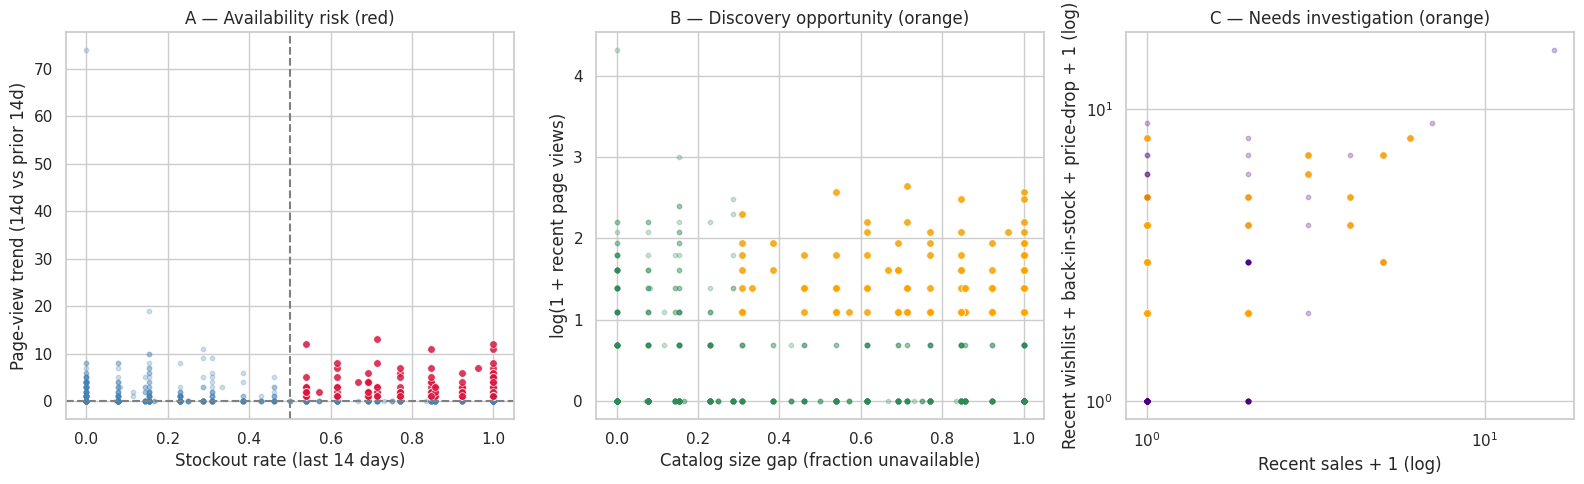

In [30]:
# Visualise the three sets ----
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].scatter(prod['r_stockout'], prod['pv_trend'],
                alpha=0.25, s=10, color='steelblue')
axes[0].scatter(product_a['r_stockout'], product_a['pv_trend'],
                alpha=0.8, s=30, color='crimson',
                edgecolor='white', linewidth=0.5)
axes[0].axhline(TREND_THRESHOLD,    ls='--', color='grey')
axes[0].axvline(STOCKOUT_THRESHOLD, ls='--', color='grey')
axes[0].set_xlabel('Stockout rate (last 14 days)')
axes[0].set_ylabel('Page-view trend (14d vs prior 14d)')
axes[0].set_title('A — Availability risk (red)')

axes[1].scatter(prod['catalog_size_gap'], np.log1p(prod['r_pv']),
                alpha=0.25, s=10, color='seagreen')
axes[1].scatter(product_b['catalog_size_gap'], np.log1p(product_b['r_pv']),
                alpha=0.8, s=30, color='orange',
                edgecolor='white', linewidth=0.5)
axes[1].set_xlabel('Catalog size gap (fraction unavailable)')
axes[1].set_ylabel('log(1 + recent page views)')
axes[1].set_title('B — Discovery opportunity (orange)')

x_all = prod['r_sales'] + 1
y_all = prod['r_wl'] + prod['r_bi'] + prod['r_pdalert'] + 1
x_c   = product_c['r_sales'] + 1
y_c   = product_c['r_wl'] + product_c['r_bi'] + product_c['r_pdalert'] + 1
axes[2].scatter(x_all, y_all, alpha=0.25, s=10, color='indigo')
axes[2].scatter(x_c, y_c, alpha=0.8, s=30, color='orange',
                edgecolor='white', linewidth=0.5)
axes[2].set_xscale('log'); axes[2].set_yscale('log')
axes[2].set_xlabel('Recent sales + 1 (log)')
axes[2].set_ylabel('Recent wishlist + back-in-stock + price-drop + 1 (log)')
axes[2].set_title('C — Needs investigation (orange)')

plt.tight_layout(); plt.show()